<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-kalshi/blob/main/notebooks/04_route_across_the_archive_boundary.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-kalshi/blob/main/notebooks/README.md)


# An empty live tape can mean the data moved

Which endpoint owns a timestamp, and how do archived executions relate to a settled payoff? Read the boundary before interpreting the archive, then review contracts by a clearly defined settlement gap.

**Synthetic data, real SQL worker.** Every `DEMOWX` contract, event, price, quantity, timestamp and source URL in this example is fictional. A strict loopback HTTP server supplies the declared responses to the published worker; there is no live fallback and no authentication. The helper creates an empty temporary SQL secret directory with persistent secrets disabled. Prices are USD per one-dollar YES contract, quantities are contracts, and all times are UTC.

In [1]:
GAP_CENTS = 30  # integer 0..100; experiment: 60

Install the shared **base** package for Colab. The local locked environment adds its `[runner]` extra. The next cell validates the current kernel before importing the companion.

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.0":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.0"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the kernel, then run all cells.")

In [3]:
from vgi_notebooks import check_runtime, prepare

check_runtime()
prepare("kalshi-surfaces")
import kalshi_surfaces as example  # noqa: E402

example.initialize(globals(), "archive")

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
SET TimeZone='UTC';
ATTACH 'kalshi' (TYPE vgi,
    LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-kalshi@v1.3.0 vgi-kalshi',
    auth 'off');

,Success


Market settlement and trade creation have separate cutoffs. The worker exposes these as a one-row table. Classify illustrative timestamps for each kind rather than treating one date as a universal boundary. The order and position cutoff fields are not account access; this released worker exposes no order or position functions.

In [5]:
%%sql
CREATE TABLE archive_cutoff AS SELECT * FROM kalshi.main.historical_cutoff;
CREATE TABLE routing AS
SELECT requested_time,
       CASE WHEN requested_time < market_settled_ts THEN 'archive' ELSE 'live' END AS markets_source,
       CASE WHEN requested_time < trades_created_ts THEN 'archive' ELSE 'live' END AS trades_source
FROM (VALUES (TIMESTAMPTZ '2026-11-09 00:00:00+00'),
             (TIMESTAMPTZ '2026-11-10 00:00:00+00'),
             (TIMESTAMPTZ '2026-11-11 00:00:00+00'),
             (TIMESTAMPTZ '2026-11-12 00:00:00+00'),
             (TIMESTAMPTZ '2026-11-13 00:00:00+00')) t(requested_time)
CROSS JOIN archive_cutoff;

,Count


In [6]:
%%sql routing <<
SELECT * FROM routing ORDER BY requested_time;

In [7]:
display(routing)

,requested_time,markets_source,trades_source
0,2026-11-09 00:00:00+00:00,archive,archive
1,2026-11-10 00:00:00+00:00,live,archive
2,2026-11-11 00:00:00+00:00,live,archive
3,2026-11-12 00:00:00+00:00,live,live
4,2026-11-13 00:00:00+00:00,live,live


The fixture contains three settled DEMOWX contracts. Materialize their archive rows, then use that bounded three-ticker set to fetch executed trades and archived candles. The archive candle signature takes only a market ticker, whereas live candles also take the series. The explicit window includes all three contracts.

In [8]:
%%sql
CREATE TABLE settled_markets AS
SELECT ticker, close_time, result, last_price_dollars, settlement_value_dollars, volume_fp
FROM kalshi.main.historical_markets('DEMOWX');

,Count


In [9]:
%%sql
CREATE TABLE archived_tape AS SELECT t.*
FROM settled_markets m, LATERAL kalshi.main.historical_trades(m.ticker) t;

,Count


In [10]:
%%sql
CREATE TABLE archived_candles AS SELECT c.*
FROM settled_markets m, LATERAL kalshi.main.historical_candlesticks(m.ticker,
    period_interval => 60, start_ts => 1793491200, end_ts => 1794268800) c;

,Count


Aggregate each source separately before joining by ticker. The last candle close and lifetime execution VWAP are historical prices; settlement is the eventual contractual payout. Our review flag uses the **absolute last-close-to-settlement difference in cents**. It is a descriptive rule, not a profit calculation.

In [11]:
%%sql
CREATE TABLE archive_comparison AS
WITH tape_summary AS (
    SELECT ticker, sum(count_fp) AS contracts,
           sum(yes_price_dollars*count_fp)/nullif(sum(count_fp),0) AS vwap_dollars
    FROM archived_tape GROUP BY ticker
), candle_summary AS (
    SELECT ticker, sum(volume_fp) AS candle_contracts,
           arg_max(price_close_dollars,end_period_ts) AS last_close_dollars
    FROM archived_candles GROUP BY ticker
)
SELECT m.*, t.contracts, t.vwap_dollars, c.candle_contracts, c.last_close_dollars,
       abs(c.last_close_dollars-m.settlement_value_dollars)*100 AS gap_cents,
       abs(c.last_close_dollars-m.settlement_value_dollars)*100 >= {{GAP_CENTS}} AS review
FROM settled_markets m JOIN tape_summary t USING(ticker) JOIN candle_summary c USING(ticker);

,Count


In [12]:
%%sql comparison <<
SELECT ticker, contracts, vwap_dollars, last_close_dollars, settlement_value_dollars, gap_cents, review
FROM archive_comparison ORDER BY ticker;

,ticker,contracts,vwap_dollars,last_close_dollars,settlement_value_dollars,gap_cents,review
0,DEMOWX-26NOV01-T20,40.0,0.7375,0.80,1.0,20.0,False
1,DEMOWX-26NOV04-T20,40.0,0.4125,0.45,0.0,45.0,True
2,DEMOWX-26NOV08-T20,40.0,0.2250,0.25,1.0,75.0,True


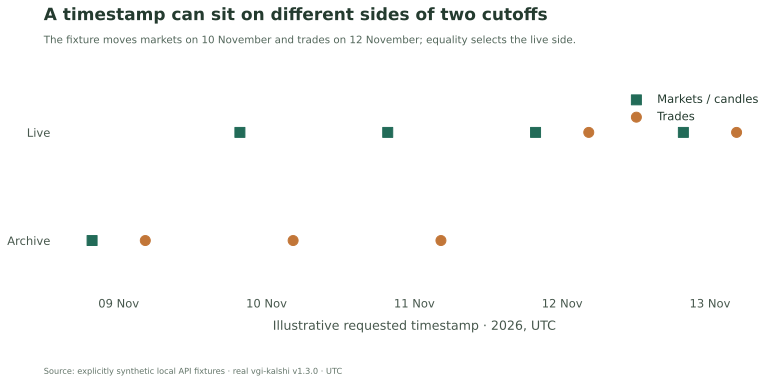

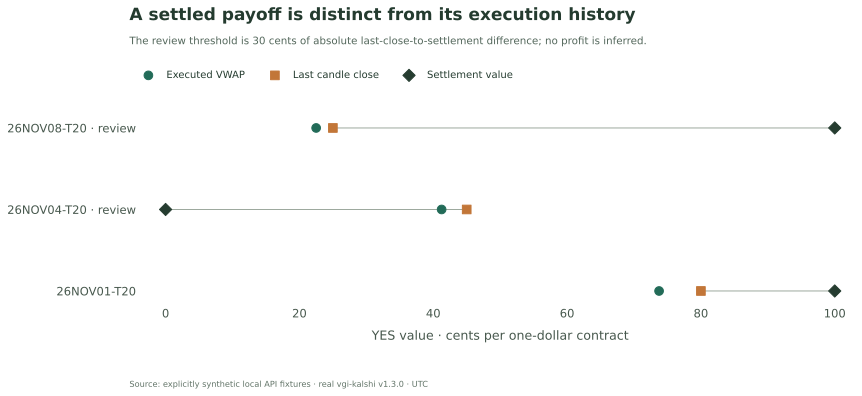

In [13]:
display(comparison)
example.archive_charts(routing, comparison, GAP_CENTS)

In [14]:
example.describe_archive(comparison, GAP_CENTS)

**2 of 3 archived contracts** have an absolute last-close-to-settlement gap of at least **30 cents**. Each tape has **40 executed contracts**, and its two candle volumes reconcile to the same total. The review flag compares two different quantities at two different times; it is neither a return calculation nor evidence that a quoted price could have been traded. Raising the threshold changes the review list without changing the archived source rows.

In [15]:
%%sql checks <<
SELECT 'one boundary row' AS invariant, (SELECT count(*) FROM archive_cutoff)=1 AS passed
UNION ALL SELECT 'kinds straddle cutoff independently', (SELECT count(*) FROM routing WHERE markets_source<>trades_source)=2
UNION ALL SELECT 'equality chooses live trade side', (SELECT trades_source='live' FROM routing WHERE requested_time=TIMESTAMPTZ '2026-11-12 00:00:00+00')
UNION ALL SELECT 'three complete contract histories', (SELECT count(*) FROM archive_comparison)=3
UNION ALL SELECT 'six unique executions', (SELECT count(*)=6 AND count(DISTINCT trade_id)=6 FROM archived_tape)
UNION ALL SELECT 'six candles', (SELECT count(*) FROM archived_candles)=6
UNION ALL SELECT 'per-contract volume reconciles', (SELECT bool_and(contracts=40 AND contracts=candle_contracts AND contracts=volume_fp) FROM archive_comparison)
UNION ALL SELECT 'last price reconciles', (SELECT bool_and(last_price_dollars=last_close_dollars) FROM archive_comparison)
UNION ALL SELECT 'binary settlement matches result', (SELECT bool_and(settlement_value_dollars=CASE WHEN result='yes' THEN 1 ELSE 0 END) FROM archive_comparison)
UNION ALL SELECT 'all settlements predate market cutoff', (SELECT bool_and(m.close_time<c.market_settled_ts) FROM settled_markets m CROSS JOIN archive_cutoff c);

In [16]:
example.check(checks)
example.audit(
    [
        "/historical/cutoff",
        "/historical/markets",
        *["/historical/trades"] * 3,
        *[f"/historical/markets/DEMOWX-26NOV{d:02d}-T20/candlesticks" for d in (1, 4, 8)],
    ]
)

,invariant,passed
0,one boundary row,True
1,kinds straddle cutoff independently,True
2,equality chooses live trade side,True
3,three complete contract histories,True
4,six unique executions,True
5,six candles,True
6,per-contract volume reconciles,True
7,last price reconciles,True
8,binary settlement matches result,True
9,all settlements predate market cutoff,True


**Verified:** 8 local GET requests, no unexpected requests, and an empty SQL secret inventory. Every displayed source row came through the released worker.

**Experiment:** raise only `GAP_CENTS` from 30 to 60. Predict which of the 20-, 45- and 75-cent gaps remain flagged. The cutoff routing, trades, candles and settlement values stay fixed; the review list changes. A date outside a live endpoint’s responsibility is not evidence that no trading occurred.

In [17]:
example.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)
